# Evolución del stack tecnológico según experiencia y rol
### Stack Overflow Developer Survey 2024 — Visualización de Datos (MPIA, ITA)

**Pregunta analítica.** ¿Cómo evoluciona el stack tecnológico y la adopción de herramientas a medida que un perfil avanza desde sus primeros años de experiencia (0-2 años) hasta roles de liderazgo o dirección (Engineering manager y Senior Executive)?

**Fuente.** Stack Overflow (2024), redistribuido en Kaggle por berkayalan (2024): <https://www.kaggle.com/datasets/berkayalan/stack-overflow-annual-developer-survey-2024>. Se usa la **versión 1** fijada en `src/utils.py` (`KAGGLE_HANDLE`).

**Estructura del notebook**

| Sección | Contenido |
|---|---|
| 1. Configuración | Librerías, rutas y estilo gráfico |
| 2. Carga de datos | Descarga reproducible y selección de columnas |
| 3. Limpieza y variables derivadas | Recodificación de experiencia, segmentación de rol, rangos, normalización de país |
| 4. Exploración (EDA) | Las cinco visualizaciones exploratorias del Avance 2 |
| 5. Control de tamaños de muestra | n de cada visualización en una sola tabla |
| 6. Visualizaciones finales | Versión estática, interactiva y exportación para BI (Avance 3) |

**Cómo ejecutarlo.** Ver `README.md` en la raíz del repositorio. El notebook corre de arriba abajo sin intervención (*Kernel → Restart & Run All*).

## 1. Configuración

In [1]:
import sys
from pathlib import Path

# Permite importar src/ al ejecutar el notebook desde notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import geopandas as gpd
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from src import utils
from src.utils import SEG_DEV, SEG_LIDER, SEG_OTRO, RANGOS_EXP

%matplotlib inline

COLOR_DEV = "#8c9bab"
COLOR_LIDER = "#1f4e79"
SEGMENTOS = [SEG_DEV, SEG_LIDER]

# Registro del tamaño de muestra de cada visualización (se resume en la sección 5)
REGISTRO_N: dict[str, dict[str, int]] = {}

print(f"pandas {pd.__version__} | geopandas {gpd.__version__} | seaborn {sns.__version__}")

pandas 3.0.2 | geopandas 1.2.0 | seaborn 0.13.2


## 2. Carga de datos

`utils.cargar_encuesta` descarga la versión fijada del dataset con `kagglehub` (queda en caché local tras la primera ejecución). Para trabajar sin conexión, define la variable de entorno `SO_SURVEY_CSV` con la ruta a una copia local de `survey_results_public.csv`.

Solo se cargan las columnas que usa el proyecto. `ResponseId` es el identificador único del encuestado y sirve como llave para las tablas en formato largo.

In [2]:
COLUMNAS = [
    "ResponseId", "YearsCodePro", "WorkExp", "DevType", "Country",
    "LanguageHaveWorkedWith", "PlatformHaveWorkedWith", "ToolsTechHaveWorkedWith",
]
df_raw = utils.cargar_encuesta(COLUMNAS)

print(f"Registros cargados: {len(df_raw):,}")
df_raw.isna().mean().mul(100).round(1).rename("% nulos").to_frame()

Registros cargados: 65,437


,% nulos
ResponseId,0.0
YearsCodePro,21.1
DevType,9.2
Country,9.9
LanguageHaveWorkedWith,8.7
PlatformHaveWorkedWith,35.3
ToolsTechHaveWorkedWith,19.8
WorkExp,54.7


## 3. Limpieza y variables derivadas

Toda la limpieza se hace **una sola vez** sobre `base`. Cada visualización filtra después las filas que necesita y registra su tamaño de muestra. No se eliminan filas en esta sección: los nulos se conservan y se descartan solo en la visualización que lo requiere.

### 3.1 Experiencia profesional (`YearsCodePro`)

La columna viene como texto. Se recodifica `"Less than 1 year"` → 0 y `"More than 50 years"` → 51 (cota inferior). `WorkExp` (años de experiencia laboral total) ya es numérica y se conserva para contrastar con `YearsCodePro` en el grupo de liderazgo, donde los años programando pueden subestimar la trayectoria.

In [3]:
base = df_raw.copy()
base["YearsCodePro"] = utils.limpiar_experiencia(base["YearsCodePro"])
base["WorkExp"] = pd.to_numeric(base["WorkExp"], errors="coerce")

print(f"YearsCodePro válidos: {base['YearsCodePro'].notna().sum():,} "
      f"({base['YearsCodePro'].notna().mean():.1%})")
print(f"Recodificados como 0 (menos de 1 año): {(df_raw['YearsCodePro'] == 'Less than 1 year').sum():,}")
print(f"Recodificados como 51 (más de 50 años): {(df_raw['YearsCodePro'] == 'More than 50 years').sum():,}")
base[["YearsCodePro", "WorkExp"]].describe().round(1)

YearsCodePro válidos: 51,610 (78.9%)
Recodificados como 0 (menos de 1 año): 2,856
Recodificados como 51 (más de 50 años): 50


,YearsCodePro,WorkExp
count,51610.0,29658.0
mean,10.2,11.5
std,9.1,9.2
min,0.0,0.0
25%,3.0,4.0
50%,7.0,9.0
75%,15.0,16.0
max,51.0,50.0


### 3.2 Segmento de rol (`DevType` → `Segmento`)

Regla de asignación sobre el rol principal:

| Segmento | Regla |
|---|---|
| Liderazgo y dirección | `Engineering manager` o `Senior Executive (C-Suite, VP, etc.)` |
| Desarrollo (contribuidor individual) | Roles que empiezan con `Developer, ` (con coma) |
| Otro (fuera del análisis) | Todos los demás roles y respuestas vacías |

**Corrección respecto al Avance 2.** La regla anterior usaba el prefijo `Developer` sin coma, lo que metía en desarrollo a *Developer Advocate* y *Developer Experience*, que no son roles de contribuidor individual. La tabla completa del mapeo se exporta a `data/processed/mapeo_segmentos.csv`.

In [4]:
base["RolPrincipal"] = base["DevType"].str.split(";").str[0].str.strip()
base["Segmento"] = utils.segmentar_rol(base["DevType"])

mapeo = (
    base.groupby(["Segmento", "RolPrincipal"], dropna=False)
    .size().rename("n").reset_index()
    .sort_values(["Segmento", "n"], ascending=[True, False])
)
utils.DIR_PROCESADOS.mkdir(parents=True, exist_ok=True)
mapeo.to_csv(utils.DIR_PROCESADOS / "mapeo_segmentos.csv", index=False)

display(base["Segmento"].value_counts().to_frame("n"))
mapeo[mapeo["Segmento"] != SEG_OTRO]

,n
Segmento,
Desarrollo (contribuidor individual),39448
Otro,23877
Liderazgo y dirección,2112


,Segmento,RolPrincipal,n
6,Desarrollo (contribuidor individual),"Developer, full-stack",18260
2,Desarrollo (contribuidor individual),"Developer, back-end",9928
5,Desarrollo (contribuidor individual),"Developer, front-end",3349
3,Desarrollo (contribuidor individual),"Developer, desktop or enterprise applications",2493
8,Desarrollo (contribuidor individual),"Developer, mobile",2021
4,Desarrollo (contribuidor individual),"Developer, embedded applications or devices",1623
7,Desarrollo (contribuidor individual),"Developer, game or graphics",706
0,Desarrollo (contribuidor individual),"Developer, AI",543
1,Desarrollo (contribuidor individual),"Developer, QA or test",525
9,Liderazgo y dirección,Engineering manager,1275


### 3.3 Rango de experiencia (variable ordinal)

`YearsCodePro` se discretiza en seis rangos: 0-2, 3-5, 6-10, 11-15, 16-20 y 20+. La variable resultante es categórica **ordenada**, de modo que respeta la progresión en el eje X.

In [5]:
base["Rango"] = utils.rango_experiencia(base["YearsCodePro"])
pd.crosstab(base["Rango"], base["Segmento"], margins=True, margins_name="Total")

Segmento,Desarrollo (contribuidor individual),Liderazgo y dirección,Otro,Total
Rango,,,,
0-2,6422,16,3225,9663
3-5,8232,104,2498,10834
6-10,9504,415,2734,12653
11-15,5158,424,1351,6933
16-20,3387,342,963,4692
20+,4722,497,1616,6835
Total,37425,1798,12387,51610


### 3.4 País → código ISO-3

Se normaliza `Country` a código de tres letras para unirlo con la geometría de Natural Earth (llave `ADM0_A3`). Los nombres que `pycountry` no resuelve se corrigen con el diccionario `EXCEPCIONES_PAIS` de `src/utils.py`. *Nomadic* queda fuera del mapa por no corresponder a un territorio.

In [6]:
mapa_iso = {pais: utils.a_iso3(pais) for pais in base["Country"].dropna().unique()}
base["ISO3"] = base["Country"].map(mapa_iso)

sin_iso = sorted(p for p, c in mapa_iso.items() if c is None)
print(f"Países distintos: {len(mapa_iso)} | sin código ISO: {sin_iso}")

Países distintos: 185 | sin código ISO: ['Nomadic']


### 3.5 Base limpia

Se exporta la tabla de encuestados con las variables derivadas. Es la fuente común para las visualizaciones finales y para la herramienta de BI.

In [7]:
COLUMNAS_BASE = ["ResponseId", "YearsCodePro", "WorkExp", "RolPrincipal", "Segmento", "Rango", "Country", "ISO3"]
base[COLUMNAS_BASE].to_csv(utils.DIR_PROCESADOS / "encuestados.csv", index=False)
print(f"Exportado: data/processed/encuestados.csv ({len(base):,} filas)")
base[COLUMNAS_BASE].head()

Exportado: data/processed/encuestados.csv (65,437 filas)


,ResponseId,YearsCodePro,WorkExp,RolPrincipal,Segmento,Rango,Country,ISO3
0,1,NaN,NaN,NaN,Otro,NaN,United States of America,USA
1,2,17.0,17.0,"Developer, full-stack",Desarrollo (contribuidor individual),16-20,United Kingdom of Great Britain and Northern I...,GBR
2,3,27.0,NaN,Developer Experience,Otro,20+,United Kingdom of Great Britain and Northern I...,GBR
3,4,NaN,NaN,"Developer, full-stack",Desarrollo (contribuidor individual),NaN,Canada,CAN
4,5,NaN,NaN,"Developer, full-stack",Desarrollo (contribuidor individual),NaN,Norway,NOR


## 4. Exploración de datos (EDA)

Reproducción de las cinco visualizaciones del Avance 2 a partir de `base`. Los resultados pueden diferir ligeramente de la entrega anterior por las dos correcciones de limpieza: la regla de segmentación (3.2) y el denominador de adopción (4.4).

### 4.1 Univariada — Distribución de `YearsCodePro`

`YearsCodePro` es **cuantitativa discreta** (años enteros). Se usa `discrete=True` para que cada barra corresponda a un año exacto: con el binning automático, los intervalos irregulares generaban un patrón de sierra que no existe en los datos. Los picos en múltiplos de 5 se deben al redondeo de los encuestados.

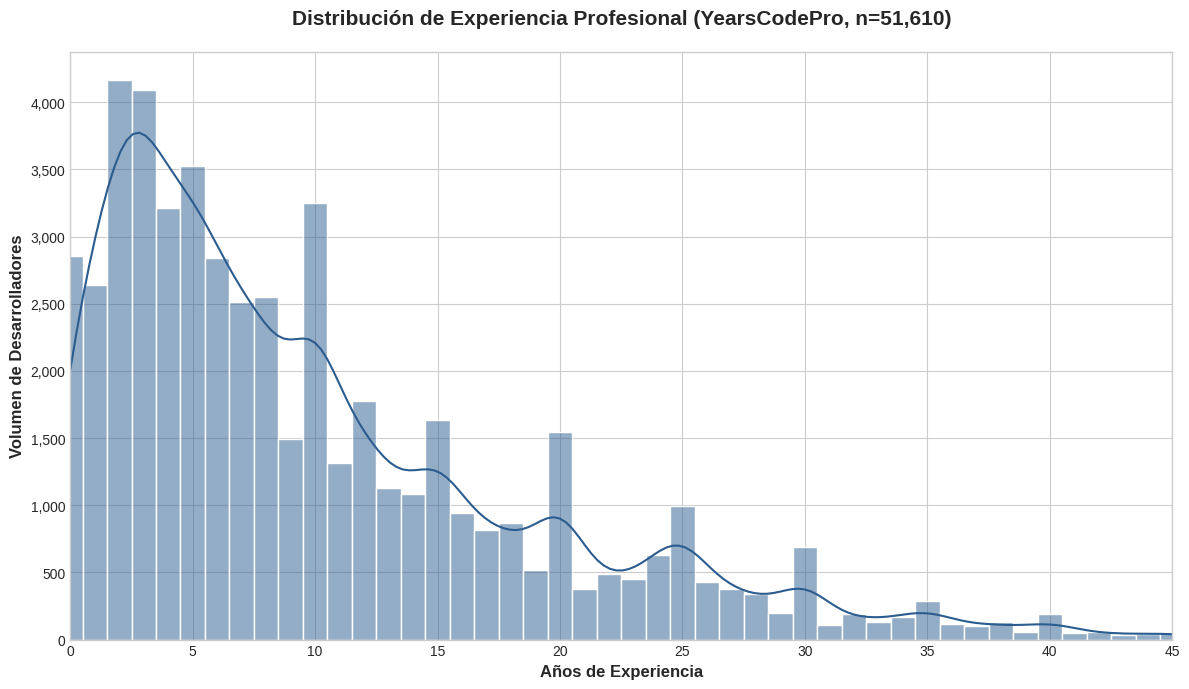

Registros con más de 45 años (fuera del eje): 120


In [8]:
df_uni = base.dropna(subset=["YearsCodePro"])
REGISTRO_N["4.1 Univariada"] = {"Total": len(df_uni)}
fuera_rango = (df_uni["YearsCodePro"] > 45).sum()

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(12, 7))
sns.histplot(data=df_uni, x="YearsCodePro", discrete=True, kde=True,
             color="#2b5c8f", edgecolor="white", ax=ax)

ax.set_title(f"Distribución de Experiencia Profesional (YearsCodePro, n={len(df_uni):,})",
             fontsize=15, pad=20, fontweight="bold")
ax.set_xlabel("Años de Experiencia", fontsize=12, fontweight="bold")
ax.set_ylabel("Volumen de Desarrolladores", fontsize=12, fontweight="bold")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.set_xlim(0, 45)

fig.tight_layout()
utils.guardar_figura(fig, "4_1_univariada_years_code_pro.png")
plt.show()
print(f"Registros con más de 45 años (fuera del eje): {fuera_rango:,}")

### 4.2 Bivariada — Experiencia por rol principal

Boxplot de `YearsCodePro` para tres roles de desarrollo y los dos de liderazgo. Gris para desarrollo y azul para liderazgo; la mediana se escribe sobre cada caja.

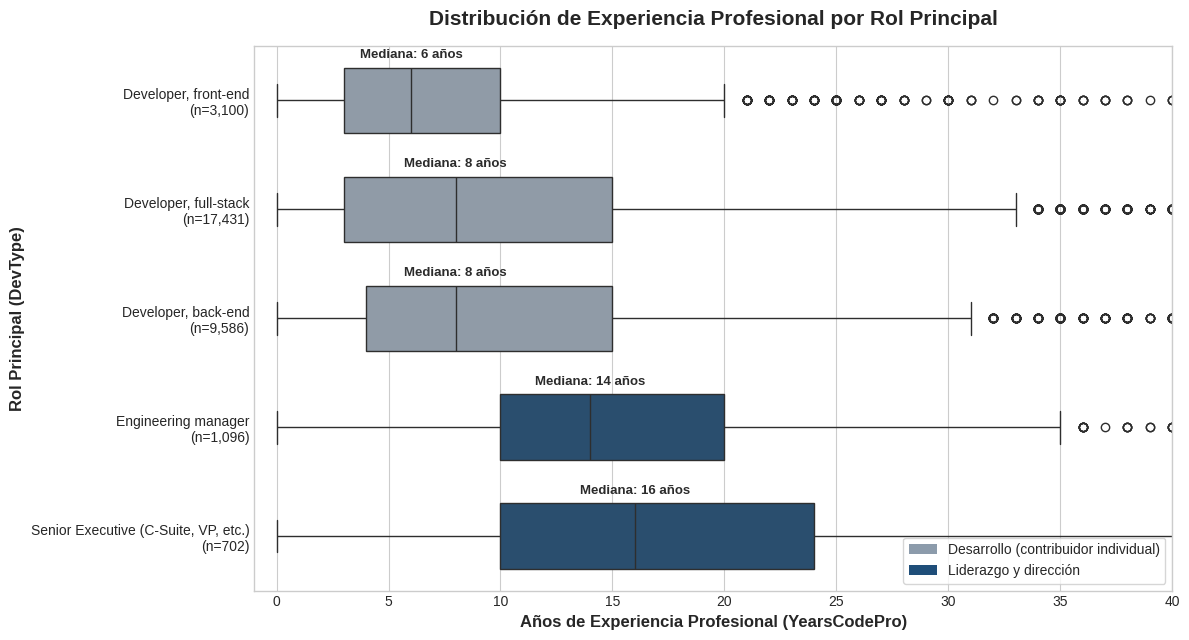

In [9]:
ROLES_BIVARIADA = [
    "Developer, front-end",
    "Developer, full-stack",
    "Developer, back-end",
    "Engineering manager",
    "Senior Executive (C-Suite, VP, etc.)",
]
df_biv = base[base["RolPrincipal"].isin(ROLES_BIVARIADA)].dropna(subset=["YearsCodePro"])

resumen = df_biv.groupby("RolPrincipal")["YearsCodePro"].agg(["median", "size"]).reindex(ROLES_BIVARIADA)
REGISTRO_N["4.2 Bivariada"] = (
    df_biv.groupby("Segmento").size().reindex(SEGMENTOS, fill_value=0).astype(int).to_dict()
)
etiquetas_y = [f"{rol}\n(n={int(resumen.loc[rol, 'size']):,})" for rol in ROLES_BIVARIADA]
colores = {rol: COLOR_DEV if rol.startswith("Developer") else COLOR_LIDER for rol in ROLES_BIVARIADA}

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(12, 6.5))
sns.boxplot(data=df_biv, x="YearsCodePro", y="RolPrincipal", order=ROLES_BIVARIADA,
            hue="RolPrincipal", palette=colores, legend=False, width=0.6, ax=ax)

for i, rol in enumerate(ROLES_BIVARIADA):
    mediana = resumen.loc[rol, "median"]
    ax.text(mediana, i - 0.36, f"Mediana: {mediana:.0f} años",
            ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#2b2b2b")

ax.set_yticks(range(len(ROLES_BIVARIADA)))
ax.set_yticklabels(etiquetas_y, fontsize=10)
ax.set_title("Distribución de Experiencia Profesional por Rol Principal", fontsize=15, pad=15, fontweight="bold")
ax.set_xlabel("Años de Experiencia Profesional (YearsCodePro)", fontsize=12, fontweight="bold")
ax.set_ylabel("Rol Principal (DevType)", fontsize=12, fontweight="bold")
ax.set_xlim(-1, 40)
ax.legend(handles=[Patch(facecolor=COLOR_DEV, label=SEG_DEV), Patch(facecolor=COLOR_LIDER, label=SEG_LIDER)],
          loc="lower right", fontsize=10, frameon=True)

fig.tight_layout()
utils.guardar_figura(fig, "4_2_bivariada_experiencia_vs_rol.png")
plt.show()

### 4.3 Multivariada — Adopción de lenguajes por experiencia y segmento

Mapas de calor del % de adopción de los 10 lenguajes más usados, por rango de experiencia y segmento. Denominador: encuestados del grupo que respondieron `LanguageHaveWorkedWith`. Las celdas con menos de 30 encuestados quedan en gris.

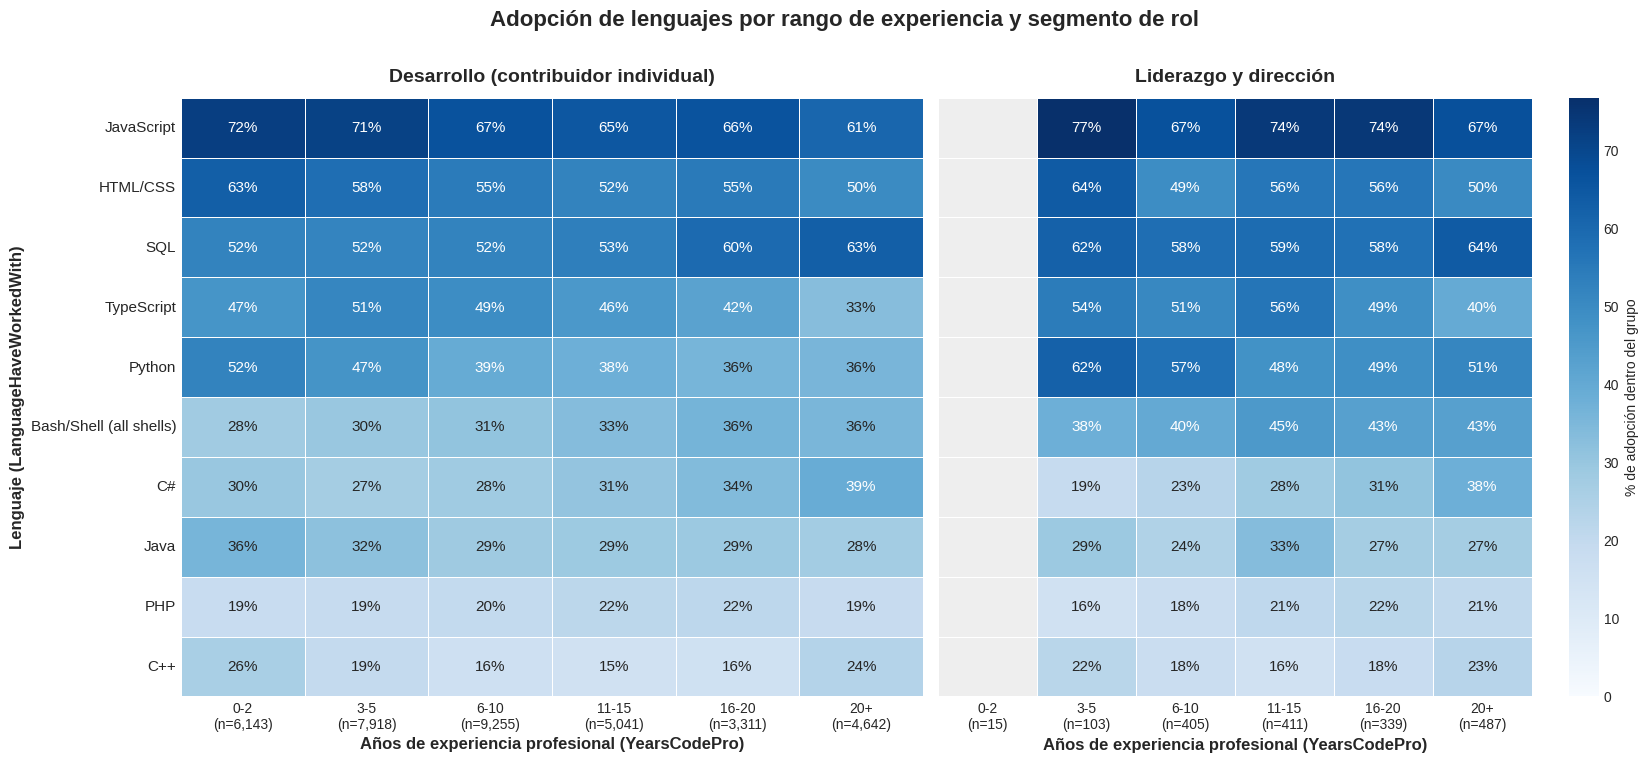

In [10]:
MIN_MUESTRA_CELDA = 30

df_lang = base[base["Segmento"].isin(SEGMENTOS)].dropna(subset=["Rango"])
top_lenguajes = utils.top_valores(df_lang, "LanguageHaveWorkedWith", n=10)
tabla_lang = utils.tabla_adopcion(df_lang, "LanguageHaveWorkedWith", por=["Segmento", "Rango"], top=top_lenguajes)
tabla_lang["adopcion"] = (tabla_lang["p"] * 100).where(tabla_lang["total"] >= MIN_MUESTRA_CELDA)

totales_lang = tabla_lang.drop_duplicates(["Segmento", "Rango"])
REGISTRO_N["4.3 Multivariada"] = totales_lang.groupby("Segmento")["total"].sum().reindex(SEGMENTOS).astype(int).to_dict()
vmax = tabla_lang["adopcion"].max()

plt.style.use("seaborn-v0_8-white")
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5), sharey=True)

for i, (ax, segmento) in enumerate(zip(axes, SEGMENTOS)):
    datos = tabla_lang[tabla_lang["Segmento"] == segmento]
    matriz = (datos.pivot(index="tecnologia", columns="Rango", values="adopcion")
              .reindex(index=top_lenguajes, columns=RANGOS_EXP))
    n_rango = (totales_lang[totales_lang["Segmento"] == segmento]
               .set_index("Rango")["total"].reindex(RANGOS_EXP, fill_value=0).astype(int))
    anotaciones = matriz.apply(lambda col: col.map(lambda v: f"{v:.0f}%" if pd.notna(v) else ""))

    sns.heatmap(matriz, ax=ax, cmap="Blues", vmin=0, vmax=vmax,
                annot=anotaciones, fmt="", annot_kws={"fontsize": 11},
                linewidths=0.5, linecolor="white",
                cbar=(i == 1), cbar_kws={"label": "% de adopción dentro del grupo"},
                xticklabels=[f"{r}\n(n={n:,})" for r, n in n_rango.items()])

    ax.set_facecolor("#eeeeee")
    ax.set_title(segmento, fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Años de experiencia profesional (YearsCodePro)", fontsize=12, fontweight="bold")
    ax.set_ylabel("Lenguaje (LanguageHaveWorkedWith)" if i == 0 else "", fontsize=12, fontweight="bold")
    ax.tick_params(axis="x", rotation=0, labelsize=10)
    ax.tick_params(axis="y", rotation=0, labelsize=11)

fig.suptitle("Adopción de lenguajes por rango de experiencia y segmento de rol",
             fontsize=16, fontweight="bold", y=1.01)
fig.tight_layout()
utils.guardar_figura(fig, "4_3_multivariada_lenguajes_experiencia_rol.png")
plt.show()

### 4.4 Comparación de grupos con intervalos de confianza (Wilson, 95%)

Proporción de cada segmento que usa las 12 plataformas y herramientas más comunes.

**Corrección respecto al Avance 2.** Antes el denominador incluía a quien respondió *cualquiera* de las dos preguntas, de modo que alguien que dejó vacía la de plataformas contaba como "no usa AWS". Ahora cada columna usa su propio denominador: plataformas sobre quienes respondieron `PlatformHaveWorkedWith` y herramientas sobre quienes respondieron `ToolsTechHaveWorkedWith`.

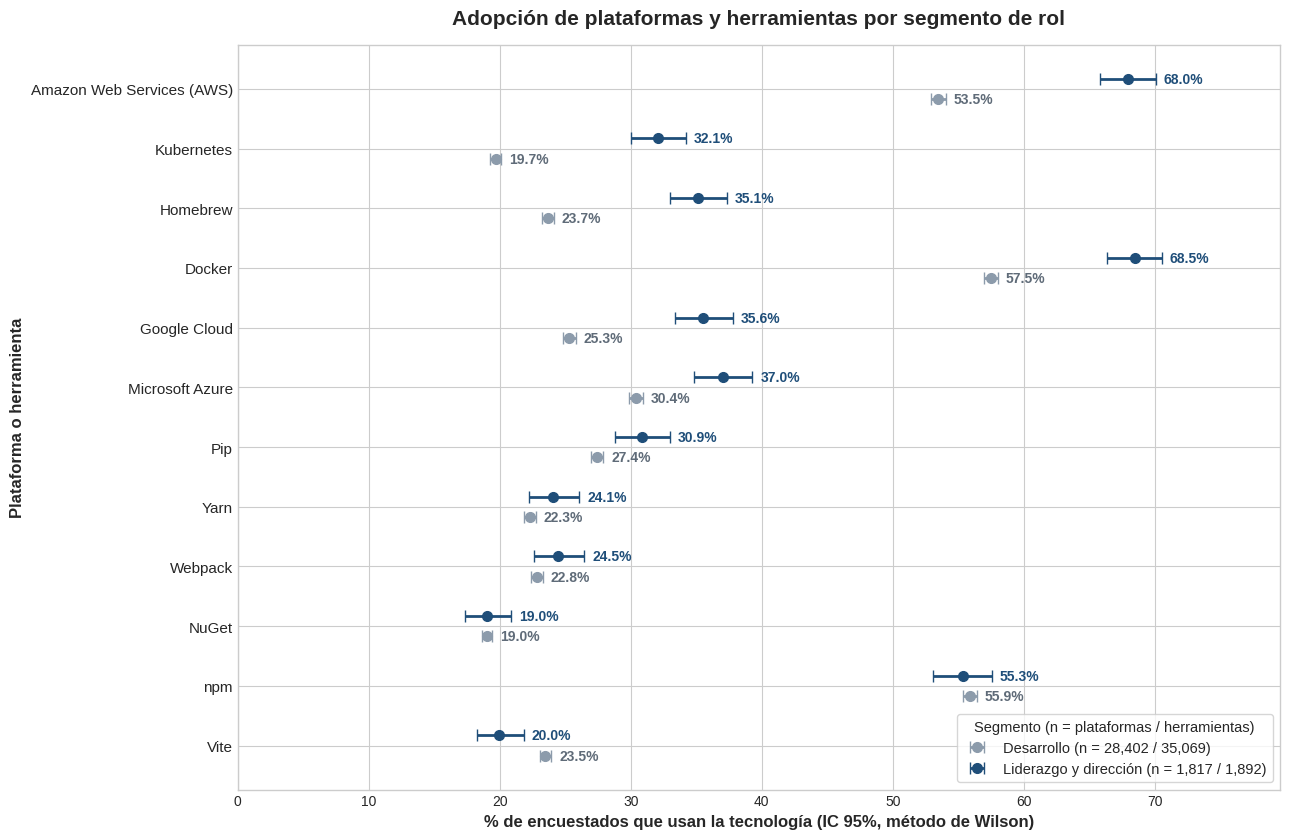

pregunta,PlatformHaveWorkedWith,ToolsTechHaveWorkedWith
Segmento,,
Desarrollo (contribuidor individual),28402,35069
Liderazgo y dirección,1817,1892


In [11]:
TOP_TECNOLOGIAS = 12

df_tec = base[base["Segmento"].isin(SEGMENTOS)]
tabla_tec = pd.concat(
    [utils.tabla_adopcion(df_tec, col, por=["Segmento"]).assign(pregunta=col)
     for col in ["PlatformHaveWorkedWith", "ToolsTechHaveWorkedWith"]],
    ignore_index=True,
)
top_tec = tabla_tec.groupby("tecnologia")["usuarios"].sum().nlargest(TOP_TECNOLOGIAS).index
tabla_tec = tabla_tec[tabla_tec["tecnologia"].isin(top_tec)]

for col in ["p", "li", "ls"]:
    tabla_tec[col] = tabla_tec[col] * 100

resultados = {seg: tabla_tec[tabla_tec["Segmento"] == seg].set_index("tecnologia") for seg in SEGMENTOS}
orden = (resultados[SEG_LIDER]["p"] - resultados[SEG_DEV]["p"]).sort_values().index.tolist()

n_preg = tabla_tec.drop_duplicates(["Segmento", "pregunta"]).pivot(index="Segmento", columns="pregunta", values="total")
REGISTRO_N["4.4 Comparación (plataformas)"] = n_preg["PlatformHaveWorkedWith"].reindex(SEGMENTOS).astype(int).to_dict()
REGISTRO_N["4.4 Comparación (herramientas)"] = n_preg["ToolsTechHaveWorkedWith"].reindex(SEGMENTOS).astype(int).to_dict()

estilos = {
    SEG_DEV: {"color": COLOR_DEV, "texto": "#5f6b78", "offset": -0.17, "nombre": "Desarrollo"},
    SEG_LIDER: {"color": COLOR_LIDER, "texto": COLOR_LIDER, "offset": 0.17, "nombre": "Liderazgo y dirección"},
}
# n distinto por pregunta: cada una usa como denominador a quien la respondió
etiquetas_n = {
    seg: f"{estilos[seg]['nombre']} (n = {n_preg.loc[seg, 'PlatformHaveWorkedWith']:,} / "
         f"{n_preg.loc[seg, 'ToolsTechHaveWorkedWith']:,})"
    for seg in SEGMENTOS
}

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(13, 8.5))
y_base = np.arange(len(orden))

for seg in SEGMENTOS:
    datos = resultados[seg].reindex(orden)
    y = y_base + estilos[seg]["offset"]
    ax.errorbar(datos["p"], y, xerr=[datos["p"] - datos["li"], datos["ls"] - datos["p"]], fmt="o",
                color=estilos[seg]["color"], ecolor=estilos[seg]["color"],
                elinewidth=2, capsize=4, markersize=7, label=etiquetas_n[seg])
    for valor, sup, yy in zip(datos["p"], datos["ls"], y):
        ax.text(sup + 0.6, yy, f"{valor:.1f}%", va="center",
                fontsize=10, fontweight="bold", color=estilos[seg]["texto"])

ax.set_yticks(y_base)
ax.set_yticklabels(orden, fontsize=11)
ax.set_xlabel("% de encuestados que usan la tecnología (IC 95%, método de Wilson)", fontsize=12, fontweight="bold")
ax.set_ylabel("Plataforma o herramienta", fontsize=12, fontweight="bold")
ax.set_title("Adopción de plataformas y herramientas por segmento de rol", fontsize=15, fontweight="bold", pad=15)
ax.set_xlim(0, tabla_tec["ls"].max() + 9)
ax.legend(loc="lower right", fontsize=10.5, frameon=True,
          title="Segmento (n = plataformas / herramientas)", title_fontsize=10.5)

fig.tight_layout()
utils.guardar_figura(fig, "4_4_comparacion_tecnologias_por_rol.png")
plt.show()
display(n_preg)

### 4.5 Geoespacial — Mediana de experiencia por país

Mapa coroplético con geometría Natural Earth 1:110m. El archivo se descarga una vez a `data/external/`. Países con menos de 100 encuestados se marcan con trama.

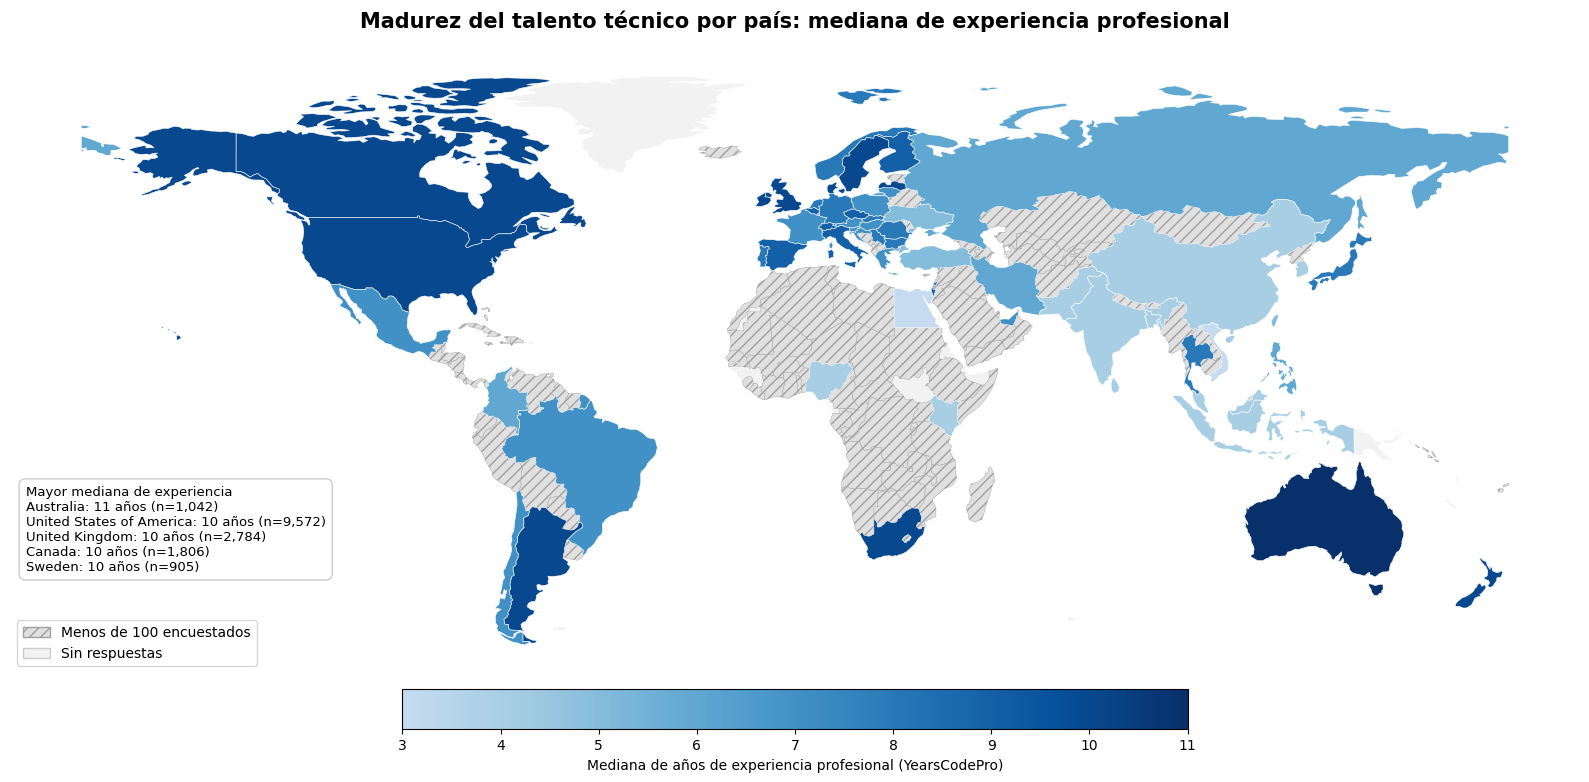

Países con geometría y n ≥ 100: 59 | con n < 100: 99
Códigos sin geometría a escala 1:110m (microestados): ['AND', 'ATG', 'BHR', 'BRB', 'CPV', 'DMA', 'FSM', 'HKG', 'IMN', 'KNA', 'LIE', 'MCO', 'MDV', 'MLT', 'MUS', 'NRU', 'SGP', 'SMR', 'WSM']
Países empatados en la mediana mínima del top 5: ['Canada', 'United States of America', 'Argentina', 'South Africa', 'Sweden', 'Latvia', 'Ireland', 'New Zealand', 'Denmark', 'United Kingdom']


In [12]:
URL_MAPA = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
MIN_MUESTRA_PAIS = 100

ruta_mapa = utils.descargar_si_falta(URL_MAPA, utils.DIR_EXTERNOS / "ne_110m_admin_0_countries.zip")

df_geo = base.dropna(subset=["ISO3", "YearsCodePro"])
REGISTRO_N["4.5 Geoespacial"] = {"Total": len(df_geo)}
resumen_pais = (df_geo.groupby("ISO3")
                .agg(mediana=("YearsCodePro", "median"), n=("YearsCodePro", "size"))
                .reset_index())

mundo = gpd.read_file(ruta_mapa)[["ADM0_A3", "NAME", "geometry"]]
mundo = mundo[mundo["ADM0_A3"] != "ATA"]  # Se excluye la Antártida
mapa = mundo.merge(resumen_pais, left_on="ADM0_A3", right_on="ISO3", how="left")

validos = mapa[mapa["n"] >= MIN_MUESTRA_PAIS]
insuficientes = mapa[mapa["n"].notna() & (mapa["n"] < MIN_MUESTRA_PAIS)]
sin_geometria = sorted(set(resumen_pais["ISO3"]) - set(mundo["ADM0_A3"]))

# Paleta azul recortada para que el tono más claro no se confunda con "sin datos"
cmap_azul = mcolors.LinearSegmentedColormap.from_list("azules", plt.cm.Blues(np.linspace(0.25, 1, 256)))

plt.style.use("default")
fig, ax = plt.subplots(figsize=(16, 8.5))
mundo.plot(ax=ax, color="#f2f2f2", edgecolor="white", linewidth=0.4)
if not insuficientes.empty:
    insuficientes.plot(ax=ax, color="#e0e0e0", edgecolor="#a0a0a0", hatch="///", linewidth=0.3)
validos.plot(ax=ax, column="mediana", cmap=cmap_azul, edgecolor="white", linewidth=0.4, legend=True,
             legend_kwds={"label": "Mediana de años de experiencia profesional (YearsCodePro)",
                          "orientation": "horizontal", "shrink": 0.5, "pad": 0.02})

ax.legend(handles=[Patch(facecolor="#e0e0e0", edgecolor="#a0a0a0", hatch="///", label=f"Menos de {MIN_MUESTRA_PAIS} encuestados"),
                   Patch(facecolor="#f2f2f2", edgecolor="#cccccc", label="Sin respuestas")],
          loc="lower left", fontsize=10, frameon=True)

top5 = validos.sort_values(["mediana", "n"], ascending=False).head(5)
texto_top = "Mayor mediana de experiencia\n" + "\n".join(
    f"{f.NAME}: {f.mediana:.0f} años (n={int(f.n):,})" for f in top5.itertuples())
ax.text(0.01, 0.30, texto_top, transform=ax.transAxes, fontsize=9.5, va="top",
        bbox={"boxstyle": "round,pad=0.5", "facecolor": "white", "edgecolor": "#cccccc"})

ax.set_title("Madurez del talento técnico por país: mediana de experiencia profesional",
             fontsize=15, fontweight="bold", pad=15)
ax.set_axis_off()

fig.tight_layout()
utils.guardar_figura(fig, "4_5_geoespacial_experiencia_por_pais.png")
plt.show()

print(f"Países con geometría y n ≥ {MIN_MUESTRA_PAIS}: {len(validos)} | con n < {MIN_MUESTRA_PAIS}: {len(insuficientes)}")
print(f"Códigos sin geometría a escala 1:110m (microestados): {sin_geometria}")
empatados = validos[validos["mediana"] == top5["mediana"].min()]["NAME"].tolist()
print(f"Países empatados en la mediana mínima del top 5: {empatados}")

## 5. Control de tamaños de muestra

Cada visualización filtra distinto (nulos en experiencia, en la pregunta de tecnologías o en país), por lo que su n varía. Esta tabla documenta esas diferencias y se cita en el reporte.

In [13]:
tabla_n = pd.DataFrame(REGISTRO_N).T.reindex(columns=["Total", *SEGMENTOS]).astype("Int64")
tabla_n.to_csv(utils.DIR_PROCESADOS / "tamanos_muestra.csv")
tabla_n

,Total,Desarrollo (contribuidor individual),Liderazgo y dirección
4.1 Univariada,51610,<NA>,<NA>
4.2 Bivariada,<NA>,30117,1798
4.3 Multivariada,<NA>,36310,1760
4.4 Comparación (plataformas),<NA>,28402,1817
4.4 Comparación (herramientas),<NA>,35069,1892
4.5 Geoespacial,50365,<NA>,<NA>


## 6. Visualizaciones finales (Avance 3)

Cada visualización final parte de una figura de la sección 4 y la lleva a mayor calidad técnica, sin cambiar la pregunta analítica ni la limpieza de la sección 3.

| Sección | Parte de | Herramienta | Estado |
|---|---|---|---|
| 6.1 Visualización estática mejorada | 4.4 | matplotlib | Completa |
| 6.2 Visualización interactiva | 4.3 | Observable Plot | Completa |
| 6.3 Exportación de datos para BI | 3.5, 4.3, 4.4 | Apache Superset | Datos exportados y validados |

### 6.1 Visualización estática mejorada — diferencia de adopción controlando la experiencia

**Qué cambia respecto a 4.4.** La figura 4.4 muestra dos proporciones por tecnología y deja al lector la resta mental entre puntos separados, con dos intervalos que no indican si la diferencia es significativa. Además, el grupo de liderazgo tiene más años de experiencia que el de desarrollo (figura 4.2), así que parte de la brecha puede deberse a la experiencia y no al rol.

**Diseño.**

- Se grafica directamente la **diferencia** liderazgo − desarrollo en puntos porcentuales, con IC 95% de Newcombe (método híbrido de Wilson; Newcombe, 1998). Un intervalo que no cruza la línea de referencia en 0 indica una diferencia distinguible de cero.
- La diferencia se calcula **dentro de cada rango de experiencia** (`Rango`), un punto por rango en la misma fila. Se omiten los rangos con menos de 30 encuestados de liderazgo (`utils.diferencia_adopcion`, `min_n=30`).
- La marca negra vertical es la diferencia sin estratificar, equivalente a 4.4, como referencia.
- Se conservan las 12 tecnologías de 4.4 y el denominador propio de cada pregunta (`utils.tabla_adopcion`).

**Justificación.** Codificar la diferencia como posición sobre una escala común es la tarea perceptual más precisa (Cleveland & McGill, 1984) y evita comparar visualmente dos puntos con sus intervalos. La estratificación por rango compara a líderes y desarrolladores con la misma experiencia, y separa así el efecto del rol del efecto de la experiencia. El rango se codifica con una escala secuencial azul porque es una variable ordinal (Munzner, 2014). Como cinco tonos de un mismo azul son difíciles de distinguir, el rango también se codifica con el orden vertical fijo dentro de cada fila y con etiquetas directas en la fila inferior.

In [14]:
PREGUNTAS_TEC = ["PlatformHaveWorkedWith", "ToolsTechHaveWorkedWith"]

def diferencias_por(datos: pd.DataFrame, por: list[str]) -> pd.DataFrame:
    """Diferencia liderazgo − desarrollo (pp) para las tecnologías de 4.4, cada pregunta con su denominador."""
    tablas = pd.concat(
        [utils.tabla_adopcion(datos, col, por=["Segmento", *por]).assign(pregunta=col) for col in PREGUNTAS_TEC],
        ignore_index=True,
    )
    tablas = tablas[tablas["tecnologia"].isin(top_tec)]
    dif = pd.concat(
        [utils.diferencia_adopcion(t, por=por, min_n=MIN_MUESTRA_CELDA).assign(pregunta=preg)
         for preg, t in tablas.groupby("pregunta")],
        ignore_index=True,
    )
    dif[["d", "li", "ls"]] = dif[["d", "li", "ls"]] * 100
    return dif

# Diferencia global (sin estratificar), equivalente a la figura 4.4
dif_global = diferencias_por(df_tec, por=[]).set_index("tecnologia")

# Diferencia dentro de cada rango de experiencia; diferencia_adopcion descarta rangos con n < 30
df_tec_rango = df_tec.dropna(subset=["Rango"])
dif_rango = diferencias_por(df_tec_rango, por=["Rango"])
rangos_61 = [r for r in RANGOS_EXP if r in set(dif_rango["Rango"].astype(str))]
omitidos_61 = [r for r in RANGOS_EXP if r not in rangos_61]

n_61 = dif_rango.drop_duplicates(["Rango", "pregunta"])
for preg, etiqueta in zip(PREGUNTAS_TEC, ["plataformas", "herramientas"]):
    sub = n_61[n_61["pregunta"] == preg]
    REGISTRO_N[f"6.1 Estática ({etiqueta})"] = {SEG_DEV: int(sub["n_a"].sum()), SEG_LIDER: int(sub["n_b"].sum())}

print(f"Rangos incluidos: {rangos_61} | omitidos (n de liderazgo < {MIN_MUESTRA_CELDA}): {omitidos_61}")
display(n_61.pivot(index="Rango", columns="pregunta", values="n_b").rename_axis(columns="n liderazgo"))
(dif_rango.assign(celda=lambda x: x["d"].map("{:+.1f}".format)
                  + " [" + x["li"].map("{:.1f}".format) + ", " + x["ls"].map("{:.1f}".format) + "]")
 .pivot(index="tecnologia", columns="Rango", values="celda")
 .reindex(index=dif_global["d"].sort_values(ascending=False).index, columns=rangos_61))

Rangos incluidos: ['3-5', '6-10', '11-15', '16-20', '20+'] | omitidos (n de liderazgo < 30): ['0-2']


n liderazgo,PlatformHaveWorkedWith,ToolsTechHaveWorkedWith
Rango,,
3-5,92,91
6-10,351,378
11-15,373,383
16-20,310,320
20+,420,448


Rango,3-5,6-10,11-15,16-20,20+
tecnologia,,,,,
Amazon Web Services (AWS),"+4.8 [-5.5, 14.4]","+5.2 [-0.1, 10.2]","+13.1 [8.2, 17.7]","+19.4 [14.0, 24.2]","+14.8 [9.9, 19.3]"
Kubernetes,"+6.6 [-1.3, 16.4]","+8.7 [4.1, 13.6]","+13.9 [9.0, 19.0]","+9.8 [4.6, 15.3]","+6.9 [2.9, 11.4]"
Homebrew,"+7.8 [-1.0, 18.1]","+9.8 [5.0, 14.9]","+12.5 [7.6, 17.6]","+8.2 [3.0, 13.7]","+13.0 [8.6, 17.6]"
Docker,"+11.6 [1.5, 19.9]","+6.9 [1.9, 11.5]","+13.6 [8.8, 17.8]","+10.9 [5.4, 15.9]","+12.6 [7.9, 17.2]"
Google Cloud,"+4.0 [-4.5, 14.1]","+10.9 [5.8, 16.2]","+13.2 [8.2, 18.4]","+12.3 [6.9, 18.1]","+8.2 [3.8, 12.9]"
Microsoft Azure,"+1.3 [-7.1, 11.3]","+1.7 [-3.0, 6.8]","-0.1 [-4.9, 5.0]","+1.2 [-4.4, 7.0]","+3.3 [-1.7, 8.4]"
Pip,"+12.5 [2.6, 22.7]","+7.1 [2.5, 12.1]","+7.0 [2.5, 11.9]","+6.8 [1.9, 12.2]","+10.6 [6.3, 15.1]"
Yarn,"+0.8 [-7.2, 10.7]","-0.8 [-5.0, 3.9]","+9.9 [5.2, 14.8]","+2.8 [-1.8, 8.0]","+5.3 [1.7, 9.4]"
Webpack,"-1.1 [-8.7, 8.6]","-0.8 [-5.1, 4.0]","+5.2 [0.6, 10.1]","+4.8 [-0.1, 10.1]","+4.8 [1.1, 8.9]"


In [15]:
# Tabla completa de la figura 6.1: una fila por tecnología y rango, más la fila "Global" sin estratificar.
# Proporciones, diferencias e IC en escala 0-100 (p en %, diferencias en puntos porcentuales).
diferencias_61 = (
    pd.concat([dif_global.reset_index().assign(Rango="Global"),
               dif_rango.assign(Rango=dif_rango["Rango"].astype(str))], ignore_index=True)
    .assign(p_a=lambda x: x["p_a"] * 100, p_b=lambda x: x["p_b"] * 100,
            ic_excluye_cero=lambda x: (x["li"] > 0) | (x["ls"] < 0))
    .rename(columns={"Rango": "rango", "n_a": "n_desarrollo", "n_b": "n_liderazgo",
                     "p_a": "p_desarrollo", "p_b": "p_liderazgo",
                     "d": "diferencia_pp", "li": "li_pp", "ls": "ls_pp"})
)
diferencias_61["rango"] = pd.Categorical(diferencias_61["rango"], categories=["Global", *rangos_61], ordered=True)
diferencias_61 = diferencias_61.sort_values(["tecnologia", "rango"])[
    ["tecnologia", "pregunta", "rango", "n_desarrollo", "n_liderazgo", "p_desarrollo", "p_liderazgo",
     "diferencia_pp", "li_pp", "ls_pp", "ic_excluye_cero"]
].reset_index(drop=True)
diferencias_61.to_csv(utils.DIR_PROCESADOS / "diferencias_por_rango.csv", index=False)
print(f"Exportado: data/processed/diferencias_por_rango.csv ({len(diferencias_61)} filas)")

TECNOLOGIAS_CLAVE = ["Amazon Web Services (AWS)", "Google Cloud", "Kubernetes", "Microsoft Azure", "Pip", "npm", "Vite"]
(diferencias_61[diferencias_61["tecnologia"].isin(TECNOLOGIAS_CLAVE)]
 .assign(tecnologia=lambda x: pd.Categorical(x["tecnologia"], categories=TECNOLOGIAS_CLAVE, ordered=True))
 .sort_values(["tecnologia", "rango"])
 .round(1)
 .set_index(["tecnologia", "rango"]))

Exportado: data/processed/diferencias_por_rango.csv (72 filas)


pregunta  n_desarrollo  \
tecnologia                rango                                           
Amazon Web Services (AWS) Global   PlatformHaveWorkedWith         28402   
                          3-5      PlatformHaveWorkedWith          6006   
                          6-10     PlatformHaveWorkedWith          7163   
                          11-15    PlatformHaveWorkedWith          3933   
                          16-20    PlatformHaveWorkedWith          2529   
                          20+      PlatformHaveWorkedWith          3359   
Google Cloud              Global   PlatformHaveWorkedWith         28402   
                          3-5      PlatformHaveWorkedWith          6006   
                          6-10     PlatformHaveWorkedWith          7163   
                          11-15    PlatformHaveWorkedWith          3933   
                          16-20    PlatformHaveWorkedWith          2529   
                          20+      PlatformHaveWorkedWith          3359   
Kubernetes                Global  ToolsTechHaveWorkedWith         35069   
                          3-5     ToolsTechHaveWorkedWith          7326   
                          6-10    ToolsTechHaveWorkedWith          8592   
                          11-15   ToolsTechHaveWorkedWith          4724   
                          16-20   ToolsTechHaveWorkedWith          3082   
                          20+     ToolsTechHaveWorkedWith          4129   
Microsoft Azure           Global   PlatformHaveWorkedWith         28402   
                          3-5      PlatformHaveWorkedWith          6006   
                          6-10     PlatformHaveWorkedWith          7163   
                          11-15    PlatformHaveWorkedWith          3933   
                          16-20    PlatformHaveWorkedWith          2529   
                          20+      PlatformHaveWorkedWith          3359   
Pip                       Global  ToolsTechHaveWorkedWith         35069   
                          3-5     ToolsTechHaveWorkedWith          7326   
                          6-10    ToolsTechHaveWorkedWith          8592   
                          11-15   ToolsTechHaveWorkedWith          4724   
                          16-20   ToolsTechHaveWorkedWith          3082   
                          20+     ToolsTechHaveWorkedWith          4129   
npm                       Global  ToolsTechHaveWorkedWith         35069   
                          3-5     ToolsTechHaveWorkedWith          7326   
                          6-10    ToolsTechHaveWorkedWith          8592   
                          11-15   ToolsTechHaveWorkedWith          4724   
                          16-20   ToolsTechHaveWorkedWith          3082   
                          20+     ToolsTechHaveWorkedWith          4129   
Vite                      Global  ToolsTechHaveWorkedWith         35069   
                          3-5     ToolsTechHaveWorkedWith          7326   
                          6-10    ToolsTechHaveWorkedWith          8592   
                          11-15   ToolsTechHaveWorkedWith          4724   
                          16-20   ToolsTechHaveWorkedWith          3082   
                          20+     ToolsTechHaveWorkedWith          4129   

                                  n_liderazgo  p_desarrollo  p_liderazgo  \
tecnologia                rango                                            
Amazon Web Services (AWS) Global         1817          53.5         68.0   
                          3-5              92          52.8         57.6   
                          6-10            351          57.5         62.7   
                          11-15           373          59.8         72.9   
                          16-20           310          57.4         76.8   
                          20+             420          54.3         69.0   
Google Cloud              Global         1817          25.3         35.6   
                          3-5              92          26.4     

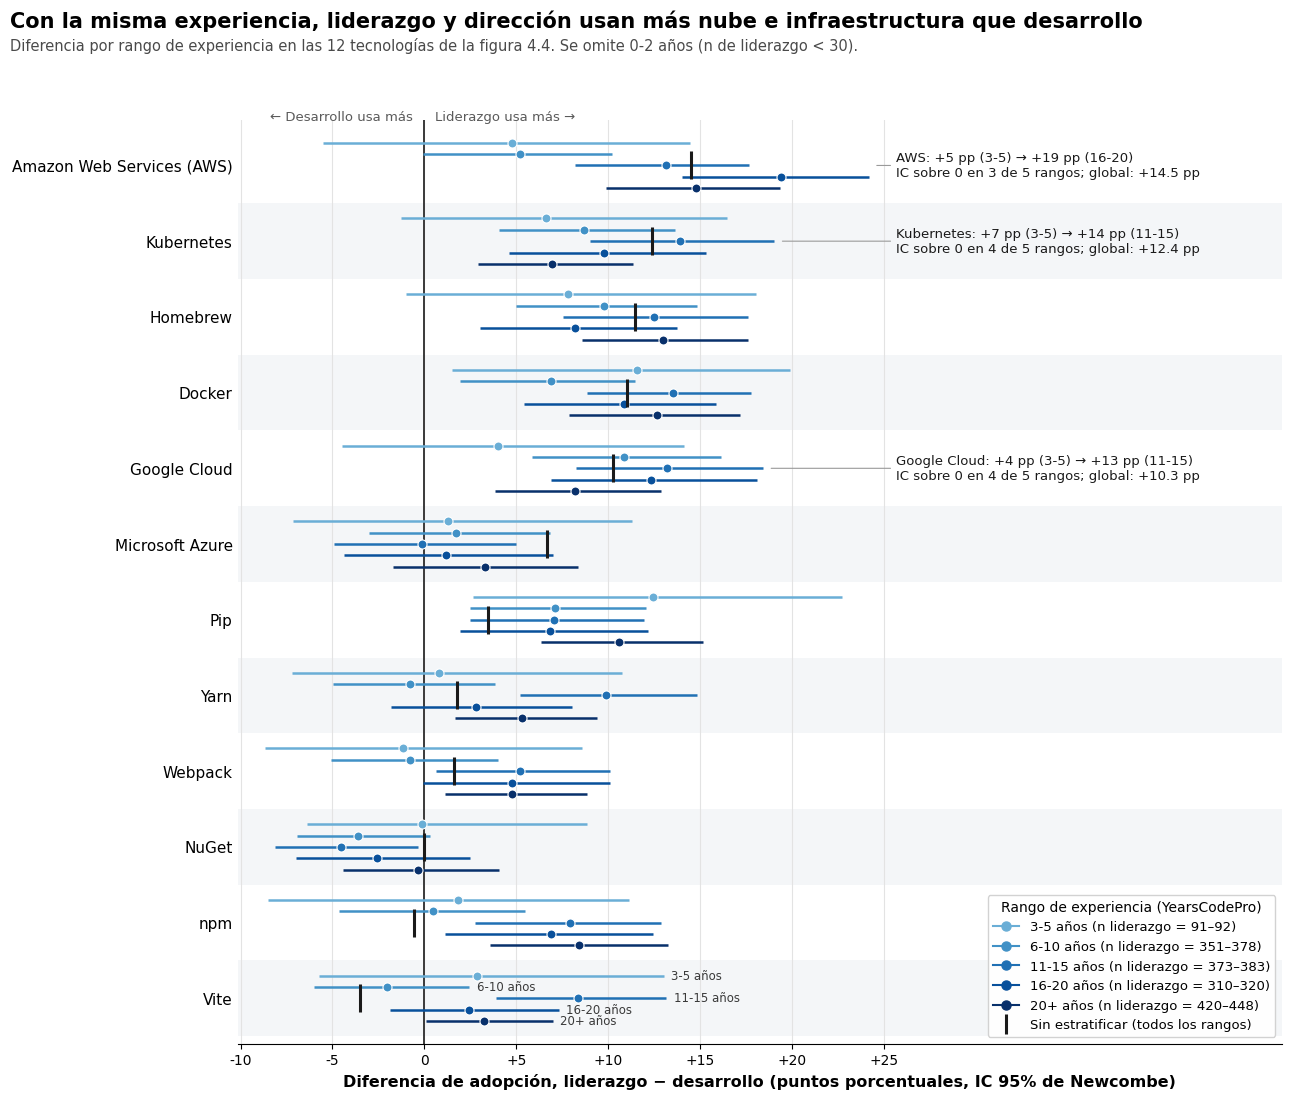

In [16]:
ANOTAR = ["Amazon Web Services (AWS)", "Google Cloud", "Kubernetes"]
NOMBRES_CORTOS = {"Amazon Web Services (AWS)": "AWS"}

orden_61 = dif_global["d"].sort_values().index.tolist()  # mayor diferencia arriba
colores_rango = dict(zip(rangos_61, plt.cm.Blues(np.linspace(0.5, 1, len(rangos_61)))))
desplazamiento = dict(zip(rangos_61, np.linspace(0.3, -0.3, len(rangos_61))))  # 3-5 arriba, 20+ abajo
n_lider = n_61.groupby("Rango", observed=True)["n_b"].agg(["min", "max"])

plt.style.use("default")
fig, ax = plt.subplots(figsize=(13, 11))

for i in range(len(orden_61)):
    if i % 2 == 0:
        ax.axhspan(i - 0.5, i + 0.5, color="#f4f6f8", zorder=0, lw=0)
ax.axvline(0, color="#3a3a3a", lw=1.4, zorder=2)

for rango in rangos_61:
    datos = dif_rango[dif_rango["Rango"] == rango].set_index("tecnologia").reindex(orden_61)
    y = np.arange(len(orden_61)) + desplazamiento[rango]
    ax.errorbar(datos["d"], y, xerr=[datos["d"] - datos["li"], datos["ls"] - datos["d"]],
                fmt="o", color=colores_rango[rango], ecolor=colores_rango[rango],
                elinewidth=1.8, capsize=0, markersize=6.5, markeredgecolor="white", markeredgewidth=0.8, zorder=3)

# Diferencia sin estratificar (la que mostraba 4.4) como referencia
ax.scatter(dif_global.loc[orden_61, "d"], np.arange(len(orden_61)), marker="|", s=420, linewidths=2.2,
           color="#1a1a1a", zorder=4)

# Etiquetas directas de rango en la fila inferior (codificación redundante al color)
fila = orden_61[0]
for rango in rangos_61:
    r = dif_rango[(dif_rango["Rango"] == rango) & (dif_rango["tecnologia"] == fila)].iloc[0]
    ax.text(r["ls"] + 0.4, desplazamiento[rango], f"{rango} años", va="center", fontsize=8.5, color="#3a3a3a")

# Anotaciones en AWS, Google Cloud y Kubernetes, calculadas a partir de los datos
x_nota = dif_rango["ls"].max() + 1.5
for tec in ANOTAR:
    sub = dif_rango[dif_rango["tecnologia"] == tec].set_index("Rango").reindex(rangos_61)
    sig = sub.index[sub["li"] > 0].tolist()
    pico = sub["d"].idxmax()
    texto = (f"{NOMBRES_CORTOS.get(tec, tec)}: +{sub.loc[rangos_61[0], 'd']:.0f} pp ({rangos_61[0]}) → "
             f"+{sub.loc[pico, 'd']:.0f} pp ({pico})\n"
             f"IC sobre 0 en {len(sig)} de {len(rangos_61)} rangos; global: +{dif_global.loc[tec, 'd']:.1f} pp")
    ax.annotate(texto, xy=(sub["ls"].max() + 0.3, orden_61.index(tec)), xytext=(x_nota, orden_61.index(tec)),
                va="center", fontsize=9.5, color="#1a1a1a",
                arrowprops={"arrowstyle": "-", "color": "#9a9a9a", "lw": 0.8})

ax.set_yticks(np.arange(len(orden_61)))
ax.set_yticklabels(orden_61, fontsize=11)
ax.set_ylim(-0.6, len(orden_61) - 0.4)
ax.set_xlim(dif_rango["li"].min() - 1.5, x_nota + 21)
ax.set_xticks(np.arange(-10, dif_rango["ls"].max() + 5, 5))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0f}" if x else "0"))
ax.grid(axis="x", color="#e3e3e3", lw=0.8, zorder=0)
for lado in ["top", "right", "left"]:
    ax.spines[lado].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Diferencia de adopción, liderazgo − desarrollo (puntos porcentuales, IC 95% de Newcombe)",
              fontsize=11.5, fontweight="bold")
ax.text(0.6, len(orden_61) - 0.45, "Liderazgo usa más →", fontsize=9.5, color="#5a5a5a", va="bottom")
ax.text(-0.6, len(orden_61) - 0.45, "← Desarrollo usa más", fontsize=9.5, color="#5a5a5a", va="bottom", ha="right")

leyenda = [Line2D([], [], marker="o", ls="-", color=colores_rango[r], markersize=6.5,
                  label=f"{r} años (n liderazgo = {n_lider.loc[r, 'min']:,}–{n_lider.loc[r, 'max']:,})")
           for r in rangos_61]
leyenda.append(Line2D([], [], marker="|", ls="none", color="#1a1a1a", markersize=14, markeredgewidth=2.2,
                      label="Sin estratificar (todos los rangos)"))
ax.legend(handles=leyenda, title="Rango de experiencia (YearsCodePro)", loc="lower right",
          fontsize=9.5, title_fontsize=10, frameon=True, framealpha=0.95, edgecolor="#d0d0d0")

fig.suptitle("Con la misma experiencia, liderazgo y dirección usan más nube e infraestructura que desarrollo",
             x=0.01, ha="left", fontsize=15, fontweight="bold", y=0.995)
fig.text(0.01, 0.958, f"Diferencia por rango de experiencia en las 12 tecnologías de la figura 4.4. "
         f"Se omite {', '.join(omitidos_61)} años (n de liderazgo < {MIN_MUESTRA_CELDA}).",
         ha="left", fontsize=10.5, color="#4a4a4a")
fig.tight_layout(rect=(0, 0, 1, 0.95))
utils.guardar_figura(fig, "6_1_estatica_diferencia_por_experiencia.png")
plt.show()

**Lectura.**

- **Nube e infraestructura.** Con la misma experiencia, liderazgo usa más Docker, Kubernetes, Google Cloud y Homebrew en todos los rangos de 6 años en adelante, con intervalos por encima de 0. En AWS la brecha crece con la experiencia: +5 pp en 3-5 y 6-10 años (IC que tocan 0) y entre +13 y +19 pp a partir de 11 años.
- **Microsoft Azure.** La diferencia global de +6.7 pp desaparece al estratificar (entre −0.1 y +3.3 pp, todos los IC cruzan 0). La brecha de 4.4 se debía a la experiencia: en desarrollo, el uso de Azure sube de 28% (3-5 años) a 43% (20+), y el grupo de liderazgo es más experimentado.
- **Vite y npm.** El signo se invierte al estratificar (paradoja de Simpson): la diferencia global es negativa, pero dentro de los rangos predomina el signo positivo. Son herramientas que pierden uso con la experiencia en ambos grupos, y liderazgo se concentra en los rangos altos. La evidencia no es igual de fuerte en las dos. En npm, la diferencia es positiva en los 5 rangos y su IC excluye 0 en 3 (11-15, 16-20 y 20+). En Vite, la estimación es positiva en 4 de 5 rangos (negativa en 6-10), pero el IC excluye 0 solo en 11-15 y en 20+, y en este último por muy poco (límite inferior de +0.1 pp). En Vite, la inversión del signo frente a la diferencia global (−3.5 pp, IC [−5.3, −1.6]) es una tendencia y no una diferencia consistente entre rangos.
- **3-5 años.** Con solo 91-92 líderes, los intervalos son amplios; las conclusiones se apoyan en los rangos de 6 años en adelante.

Limitación: la encuesta es de corte transversal; compara personas distintas en cada rango, no trayectorias individuales.

#### Comparación con la versión exploratoria

Panel para el documento: a la izquierda, la figura 4.4 (versión exploratoria); a la derecha, la versión mejorada. Ambas usan la limpieza corregida de la sección 3 y el denominador propio de cada pregunta, por lo que las cifras del panel izquierdo no son las de la entrega anterior.

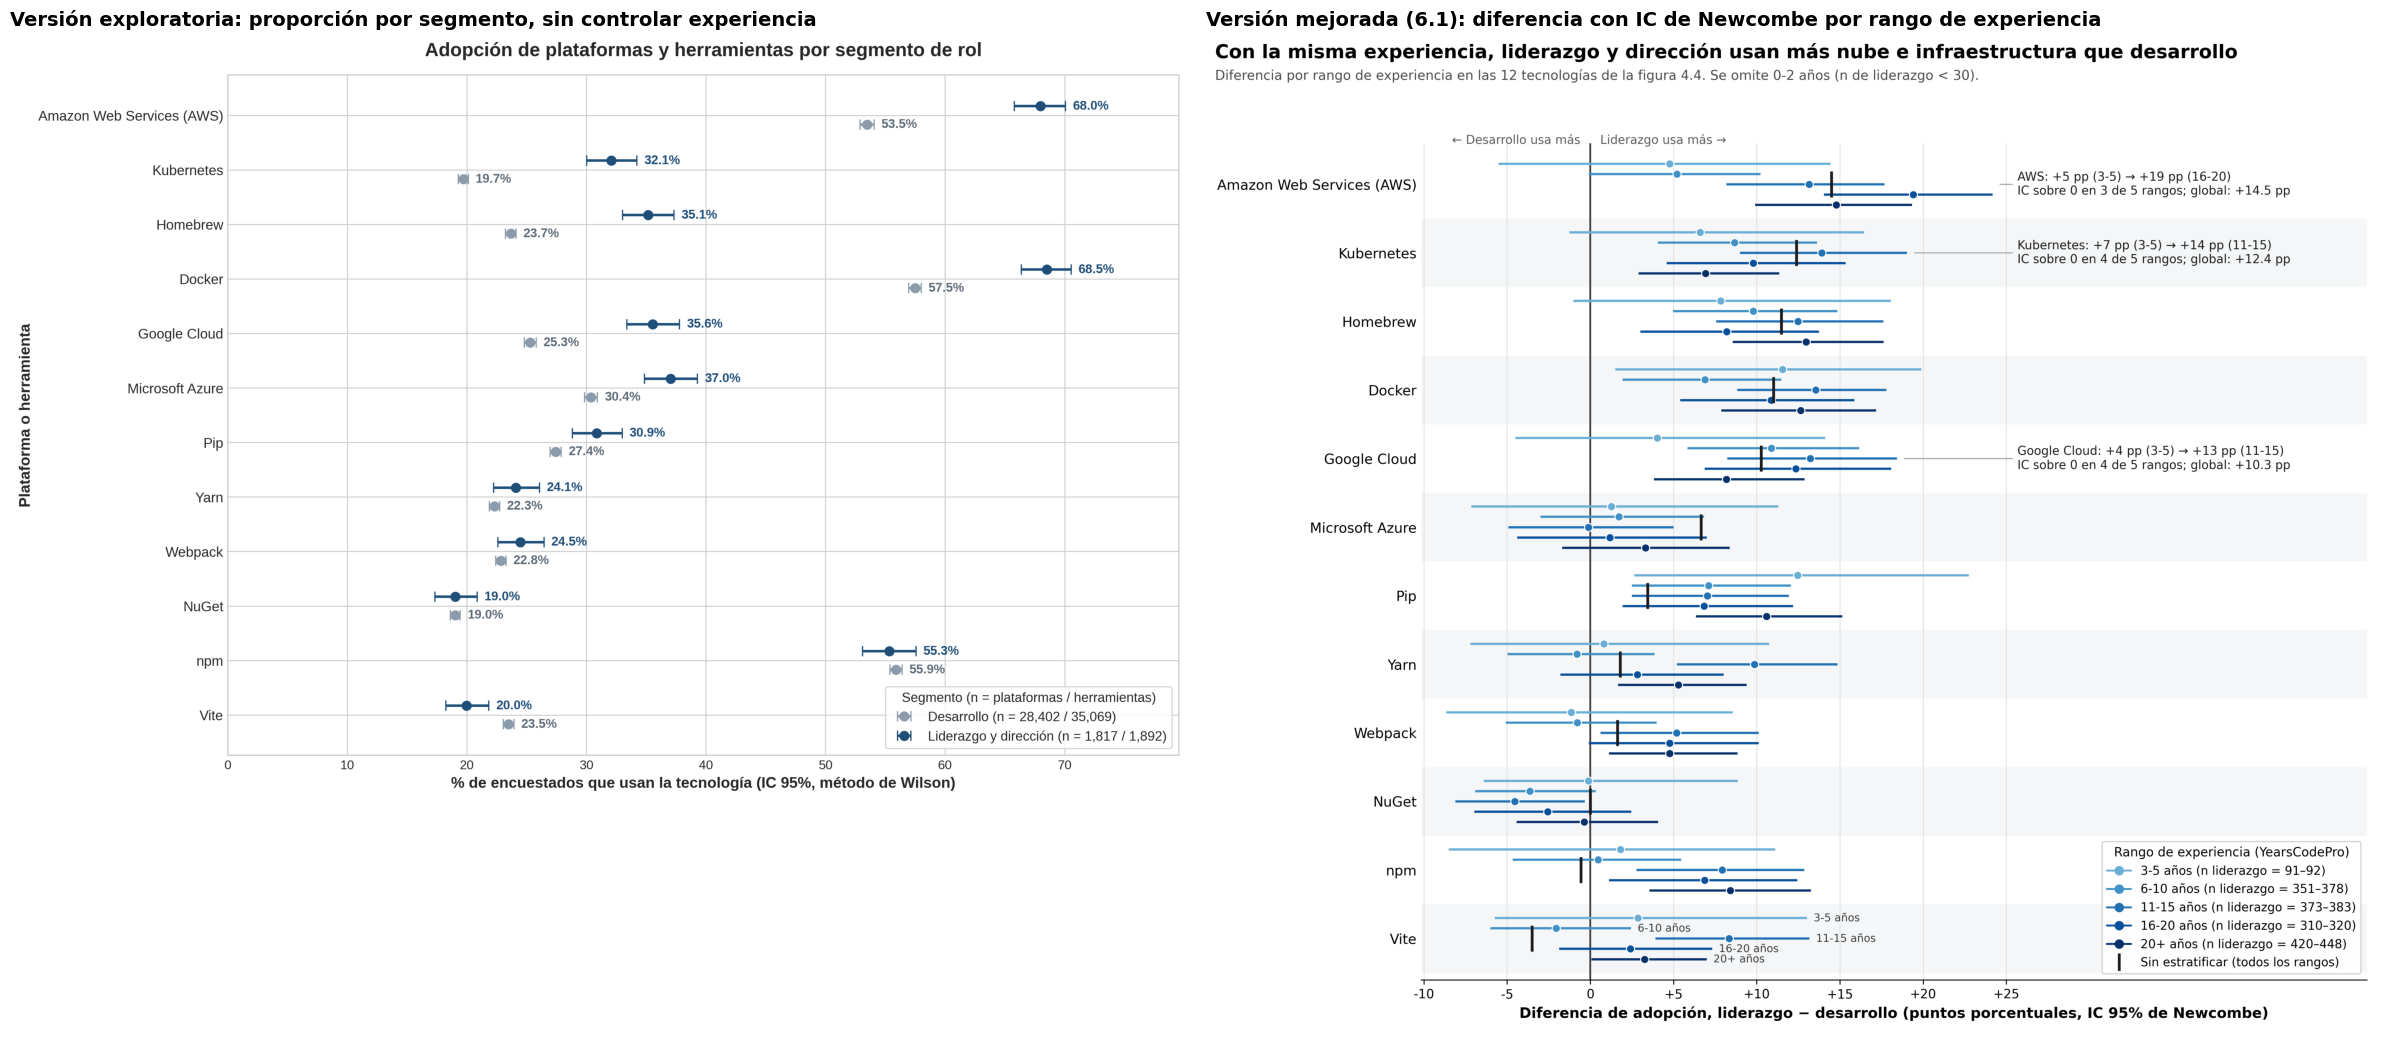

In [17]:
paneles = [
    ("4_4_comparacion_tecnologias_por_rol.png", "Versión exploratoria: proporción por segmento, sin controlar experiencia"),
    ("6_1_estatica_diferencia_por_experiencia.png", "Versión mejorada (6.1): diferencia con IC de Newcombe por rango de experiencia"),
]
fig, axes = plt.subplots(1, 2, figsize=(24, 10.5), gridspec_kw={"width_ratios": [1, 1]})
for ax, (archivo, titulo) in zip(axes, paneles):
    ax.imshow(plt.imread(utils.DIR_FIGURAS / archivo))
    ax.set_title(titulo, fontsize=14, fontweight="bold", loc="left")
    ax.set_axis_off()
    ax.set_anchor("N")  # alinea ambas figuras arriba aunque tengan distinta altura
fig.tight_layout()
utils.guardar_figura(fig, "6_1_comparacion_avance2_vs_final.png", dpi=200)
plt.show()

### 6.2 Visualización interactiva — adopción de lenguajes por país, segmento y rango

**Qué cambia respecto a 4.3.** El mapa de calor estático tiene tres problemas: el texto de las celdas es difícil de leer en los tonos intermedios, el n de cada celda y su incertidumbre no se ven, y no permite controlar por país (Estados Unidos aporta casi una quinta parte de las respuestas y pesa en el agregado).

**Diseño.** Página web con Observable Plot (`docs/index.html`, `docs/app.js`), publicada con GitHub Pages desde la carpeta `docs/`:

- Un panel por segmento (lenguaje × rango) con el % escrito en cada celda y el n de cada rango en el eje X.
- Selector de **país** y de **segmento**; la vista se guarda en la URL para compartirla.
- Tooltip (`Plot.tip`) con %, IC 95% de Wilson y usuarios/total.
- Celdas con menos de 30 encuestados en gris, sin porcentaje y con el aviso «muestra insuficiente» en el tooltip.
- Escala de color con dominio fijo 0-100%, igual en todas las vistas, para que los tonos sean comparables entre países.

**Datos.** Esta celda exporta `docs/data/adopcion_lenguajes.json` con `utils.tabla_adopcion` (`por=["pais", "Segmento", "Rango"]`) sobre los 10 lenguajes de 4.3. `pais = "Todos"` agrega a todos los encuestados y coincide con 4.3. Se incluyen los países con al menos 500 encuestados de desarrollo con experiencia válida; con menos, casi todas las celdas de liderazgo quedarían bajo el umbral. Los grupos sin encuestados se exportan con `total = 0` para que la web los pinte en gris.

**Justificación.** La interacción resuelve lo que la versión estática no puede mostrar sin saturarse: el n y el intervalo de cada celda (detalles bajo demanda) y la comparación por país sin multiplicar las figuras (Munzner, 2014).

In [18]:
MIN_DEV_PAIS = 500
DIR_WEB_DATOS = utils.ROOT / "docs" / "data"  # GitHub Pages publica la carpeta docs/

# Países con al menos 500 encuestados de desarrollo con YearsCodePro válido (Rango no nulo)
n_dev_pais = (df_lang[df_lang["Segmento"] == SEG_DEV]
              .groupby("Country").size().sort_values(ascending=False))
paises_62 = n_dev_pais[n_dev_pais >= MIN_DEV_PAIS].index.tolist()

# "Todos" usa a todos los encuestados de df_lang (cualquier país, incluso sin país)
df_web = pd.concat([
    df_lang.assign(pais="Todos"),
    df_lang[df_lang["Country"].isin(paises_62)].assign(pais=lambda x: x["Country"]),
], ignore_index=True)
tabla_web = utils.tabla_adopcion(df_web, "LanguageHaveWorkedWith",
                                 por=["pais", "Segmento", "Rango"], top=top_lenguajes)

# Rejilla completa: los grupos sin encuestados quedan con total 0 para que la web los pinte en gris
rejilla_web = pd.MultiIndex.from_product(
    [["Todos", *paises_62], SEGMENTOS, RANGOS_EXP, top_lenguajes],
    names=["pais", "Segmento", "Rango", "tecnologia"],
).to_frame(index=False)
tabla_web["Rango"] = tabla_web["Rango"].astype(str)
tabla_web = rejilla_web.merge(tabla_web, on=["pais", "Segmento", "Rango", "tecnologia"], how="left")
tabla_web[["usuarios", "total"]] = tabla_web[["usuarios", "total"]].fillna(0).astype(int)
tabla_web[["p", "li", "ls"]] = (tabla_web[["p", "li", "ls"]] * 100).round(1)

json_web = tabla_web.rename(columns={"Segmento": "segmento", "Rango": "rango", "tecnologia": "lenguaje"})[
    ["pais", "segmento", "rango", "lenguaje", "usuarios", "total", "p", "li", "ls"]
]
DIR_WEB_DATOS.mkdir(parents=True, exist_ok=True)
json_web.to_json(DIR_WEB_DATOS / "adopcion_lenguajes.json", orient="records", force_ascii=False, indent=0)

# n por país: criterio de inclusión y encuestados que respondieron la pregunta de lenguajes
n_respondieron = (json_web.drop_duplicates(["pais", "segmento", "rango"])
                  .pivot_table(index="pais", columns="segmento", values="total", aggfunc="sum"))
paises_tabla = pd.DataFrame({"n desarrollo (criterio)": n_dev_pais.reindex(paises_62)}).join(
    n_respondieron[SEGMENTOS].add_prefix("n lenguajes · "))
paises_tabla.to_csv(utils.DIR_PROCESADOS / "paises_interactiva.csv")

REGISTRO_N["6.2 Interactiva (Todos)"] = n_respondieron.loc["Todos", SEGMENTOS].astype(int).to_dict()
celdas_insuficientes = (json_web["total"] < MIN_MUESTRA_CELDA).groupby(json_web["segmento"]).mean()

print(f"Exportado: docs/data/adopcion_lenguajes.json ({len(json_web):,} filas, {len(paises_62)} países + Todos)")
print("Celdas con total < 30 por segmento:", celdas_insuficientes.map("{:.0%}".format).to_dict())
paises_tabla

Exportado: docs/data/adopcion_lenguajes.json (2,160 filas, 17 países + Todos)
Celdas con total < 30 por segmento: {'Desarrollo (contribuidor individual)': '0%', 'Liderazgo y dirección': '91%'}


,n desarrollo (criterio),n lenguajes · Desarrollo (contribuidor individual),n lenguajes · Liderazgo y dirección
Country,,,
United States of America,6456,6383,480
Germany,2957,2932,102
India,2526,2463,76
Ukraine,1989,1973,44
United Kingdom of Great Britain and Northern Ireland,1971,1952,132
Canada,1295,1276,79
France,1267,1259,70
Poland,1035,1027,26
Netherlands,965,950,30


### 6.3 Exportación de datos para Apache Superset

El dashboard de BI se construye sobre dos tablas que salen de la misma limpieza (sección 3), para que sus cifras coincidan con las figuras del notebook. Ambas van a `superset/data/`, con columnas en *snake_case* y sin acentos para que Superset y PostgreSQL no requieran comillas.

| Tabla | Grano | Uso en el dashboard |
|---|---|---|
| `encuestados.csv` | Un encuestado de desarrollo o liderazgo | KPIs: n por segmento, mediana de experiencia |
| `adopcion.csv` | País × segmento × rango × pregunta × tecnología | Adopción por segmento, con filtros |

**Decisiones de diseño.**

- `adopcion.csv` guarda **conteos** (`usuarios`, `total`), no porcentajes. Superset calcula la adopción como `SUM(usuarios) * 100 / SUM(total)` después de filtrar, de modo que el porcentaje se recalcula correctamente para cualquier combinación de país, rango y segmento. Promediar porcentajes precalculados daría el mismo peso a un grupo de 4 personas que a uno de 6,000.
- `total` es el número de encuestados del grupo que respondieron *esa* pregunta (`utils.tabla_adopcion`). Se conservan las filas con 0 usuarios; sin ellas, `SUM(total)` perdería parte del denominador.
- Los nulos se vuelven categorías explícitas (`pais = "Sin país"`, `rango = "Sin dato"`). Así, sin filtros, los totales coinciden con 4.3 y 4.4.
- Columnas auxiliares: `segmento_corto` («Desarrollo» / «Liderazgo») para leyendas legibles, y `rango_orden` (1-6, 99 para «Sin dato») porque Superset ordena el texto alfabéticamente y «11-15» quedaría antes que «3-5».
- Las columnas `pais`, `segmento` y `rango` tienen el mismo nombre en ambas tablas, de modo que un filtro nativo del dashboard actúa sobre las dos.
- Rankings por usuarios totales (denso; el mismo valor en todas las filas de la tecnología): `rank_pregunta`, dentro de cada pregunta, y `rank_plataformas_herramientas`, con plataformas y herramientas juntas. Este último reproduce la selección de la figura 4.4: con `rank_plataformas_herramientas <= 12` aparecen sus 12 tecnologías. `rank_pregunta <= 12` en esas dos preguntas devuelve 24 tecnologías (12 de cada una).

In [19]:
DIR_SUPERSET = utils.ROOT / "superset" / "data"
SIN_PAIS, SIN_RANGO = "Sin país", "Sin dato"
SEGMENTO_CORTO = {SEG_DEV: "Desarrollo", SEG_LIDER: "Liderazgo"}
# Superset ordena texto alfabéticamente ("11-15" antes que "3-5"): se exporta el orden como entero
RANGO_ORDEN = {**{r: i for i, r in enumerate(RANGOS_EXP, start=1)}, SIN_RANGO: 99}
PREGUNTAS_BI = {
    "LanguageHaveWorkedWith": "lenguajes",
    "PlatformHaveWorkedWith": "plataformas",
    "ToolsTechHaveWorkedWith": "herramientas",
}

# Nulos explícitos en país y rango: así los totales sin filtros coinciden con 4.3 y 4.4
df_bi = base[base["Segmento"].isin(SEGMENTOS)].assign(
    pais=lambda x: x["Country"].fillna(SIN_PAIS),
    Rango=lambda x: x["Rango"].astype(str).where(x["Rango"].notna(), SIN_RANGO),
)
iso3_pais = df_bi.drop_duplicates("pais").set_index("pais")["ISO3"]

def columnas_auxiliares(df: pd.DataFrame) -> pd.DataFrame:
    return df.assign(segmento_corto=df["segmento"].map(SEGMENTO_CORTO),
                     rango_orden=df["rango"].map(RANGO_ORDEN).astype(int))

# a) Una fila por encuestado de desarrollo o liderazgo
encuestados_bi = columnas_auxiliares(
    df_bi.rename(columns={"ResponseId": "response_id", "YearsCodePro": "years_code_pro",
                          "RolPrincipal": "rol_principal", "Segmento": "segmento",
                          "Rango": "rango", "ISO3": "iso3"})
)[["response_id", "years_code_pro", "rol_principal", "segmento", "segmento_corto",
   "rango", "rango_orden", "pais", "iso3"]]

# b) Conteos por país × segmento × rango × pregunta × tecnología (todas las tecnologías).
# Se conservan las filas con 0 usuarios: sin ellas, SUM(total) perdería denominadores.
adopcion_bi = pd.concat(
    [utils.tabla_adopcion(df_bi, col, por=["pais", "Segmento", "Rango"]).assign(pregunta=nombre)
     for col, nombre in PREGUNTAS_BI.items()],
    ignore_index=True,
).rename(columns={"Segmento": "segmento", "Rango": "rango"})
adopcion_bi = columnas_auxiliares(adopcion_bi.assign(iso3=adopcion_bi["pais"].map(iso3_pais)))

# Rankings por usuarios totales (todos los países, segmentos y rangos); denso: los empates comparten número.
# rank_pregunta ordena dentro de cada pregunta. rank_plataformas_herramientas ordena plataformas y herramientas
# juntas, con el mismo criterio con que la figura 4.4 elige sus 12 tecnologías (vacío en lenguajes).
usuarios_tec = adopcion_bi.groupby(["pregunta", "tecnologia"])["usuarios"].sum().reset_index()
usuarios_tec["rank_pregunta"] = (usuarios_tec.groupby("pregunta")["usuarios"]
                                 .rank(method="dense", ascending=False).astype(int))
infra = usuarios_tec["pregunta"].isin(["plataformas", "herramientas"])
usuarios_tec["rank_plataformas_herramientas"] = (usuarios_tec["usuarios"].where(infra)
                                                 .rank(method="dense", ascending=False).astype("Int64"))
adopcion_bi = adopcion_bi.merge(
    usuarios_tec.drop(columns="usuarios"), on=["pregunta", "tecnologia"], how="left", validate="many_to_one"
)[["pais", "iso3", "segmento", "segmento_corto", "rango", "rango_orden",
   "pregunta", "tecnologia", "rank_pregunta", "rank_plataformas_herramientas", "usuarios", "total"]]

DIR_SUPERSET.mkdir(parents=True, exist_ok=True)
encuestados_bi.to_csv(DIR_SUPERSET / "encuestados.csv", index=False)
adopcion_bi.to_csv(DIR_SUPERSET / "adopcion.csv", index=False)

REGISTRO_N["6.3 BI (encuestados)"] = encuestados_bi["segmento"].value_counts().reindex(SEGMENTOS).to_dict()
print(f"superset/data/encuestados.csv: {len(encuestados_bi):,} filas")
print(f"superset/data/adopcion.csv: {len(adopcion_bi):,} filas")
display(adopcion_bi.groupby("pregunta")["tecnologia"].nunique().rename("tecnologías distintas").to_frame())

superset/data/encuestados.csv: 41,560 filas
superset/data/adopcion.csv: 136,341 filas


,tecnologías distintas
pregunta,
herramientas,34
lenguajes,49
plataformas,27


**Validación.** Se agrega `adopcion.csv` sin filtros, tal como lo haría Superset, y se compara con las cifras de las figuras 4.4 y 4.3. La celda falla si alguna diferencia supera 0.05 puntos porcentuales, o si los rankings no son únicos por tecnología o no reproducen las 12 tecnologías de 4.4.

In [20]:
# Validación: lo que calcularía Superset sin filtros, SUM(usuarios) * 100 / SUM(total) por tecnología
ESPERADOS = [
    # (pregunta, tecnologia, segmento, rango o None = todos, % esperado, figura)
    ("plataformas", "Amazon Web Services (AWS)", "Desarrollo", None, 53.5, "4.4"),
    ("plataformas", "Amazon Web Services (AWS)", "Liderazgo", None, 68.0, "4.4"),
    ("plataformas", "Google Cloud", "Desarrollo", None, 25.3, "4.4"),
    ("plataformas", "Google Cloud", "Liderazgo", None, 35.6, "4.4"),
    ("herramientas", "Kubernetes", "Desarrollo", None, 19.7, "4.4"),
    ("herramientas", "Kubernetes", "Liderazgo", None, 32.1, "4.4"),
    ("lenguajes", "Python", "Desarrollo", "0-2", 52.3, "4.3"),
]
TOLERANCIA_PP = 0.05

filas_val = []
for pregunta, tec, seg, rango, esperado, figura in ESPERADOS:
    sel = adopcion_bi[(adopcion_bi["pregunta"] == pregunta) & (adopcion_bi["tecnologia"] == tec)
                      & (adopcion_bi["segmento_corto"] == seg)]
    if rango is not None:
        sel = sel[sel["rango"] == rango]
    obtenido = sel["usuarios"].sum() * 100 / sel["total"].sum()
    filas_val.append({"figura": figura, "tecnologia": tec, "segmento": seg, "rango": rango or "Todos",
                      "usuarios": sel["usuarios"].sum(), "total": sel["total"].sum(),
                      "esperado_pct": esperado, "obtenido_pct": round(obtenido, 3),
                      "diferencia_pp": round(obtenido - esperado, 3)})
validacion_bi = pd.DataFrame(filas_val)

fuera = validacion_bi[validacion_bi["diferencia_pp"].abs() > TOLERANCIA_PP]
assert fuera.empty, f"adopcion.csv no reproduce las figuras:\n{fuera}"
print(f"Validación correcta: todas las diferencias dentro de ±{TOLERANCIA_PP} pp")
display(validacion_bi)

# Rankings: el filtro de Superset debe devolver las mismas 12 tecnologías de la figura 4.4
rangos_tec = adopcion_bi.drop_duplicates(["pregunta", "tecnologia"])
assert (adopcion_bi.groupby(["pregunta", "tecnologia"])[["rank_pregunta", "rank_plataformas_herramientas"]]
        .nunique(dropna=False).max() == 1).all(), "Una tecnología tiene más de un ranking"

infra_12 = rangos_tec[rangos_tec["rank_plataformas_herramientas"] <= TOP_TECNOLOGIAS]
assert set(infra_12["tecnologia"]) == set(top_tec), "rank_plataformas_herramientas <= 12 no coincide con 4.4"

por_pregunta_12 = rangos_tec[rangos_tec["pregunta"].isin(["plataformas", "herramientas"])
                             & (rangos_tec["rank_pregunta"] <= TOP_TECNOLOGIAS)]
assert set(top_tec) <= set(por_pregunta_12["tecnologia"])
print(f"rank_plataformas_herramientas <= {TOP_TECNOLOGIAS}: las mismas {len(infra_12)} tecnologías de la figura 4.4")
print(f"rank_pregunta <= {TOP_TECNOLOGIAS} en plataformas + herramientas: {len(por_pregunta_12)} tecnologías "
      f"(12 por pregunta), que incluyen las 12 de 4.4")
infra_12.sort_values("rank_plataformas_herramientas")[
    ["pregunta", "tecnologia", "rank_pregunta", "rank_plataformas_herramientas"]].reset_index(drop=True)

Validación correcta: todas las diferencias dentro de ±0.05 pp


,figura,tecnologia,segmento,rango,usuarios,total,esperado_pct,obtenido_pct,diferencia_pp
0,4.4,Amazon Web Services (AWS),Desarrollo,Todos,15189,28402,53.5,53.479,-0.021
1,4.4,Amazon Web Services (AWS),Liderazgo,Todos,1235,1817,68.0,67.969,-0.031
2,4.4,Google Cloud,Desarrollo,Todos,7185,28402,25.3,25.298,-0.002
3,4.4,Google Cloud,Liderazgo,Todos,646,1817,35.6,35.553,-0.047
4,4.4,Kubernetes,Desarrollo,Todos,6910,35069,19.7,19.704,0.004
5,4.4,Kubernetes,Liderazgo,Todos,607,1892,32.1,32.082,-0.018
6,4.3,Python,Desarrollo,0-2,3215,6143,52.3,52.336,0.036


rank_plataformas_herramientas <= 12: las mismas 12 tecnologías de la figura 4.4
rank_pregunta <= 12 en plataformas + herramientas: 24 tecnologías (12 por pregunta), que incluyen las 12 de 4.4


,pregunta,tecnologia,rank_pregunta,rank_plataformas_herramientas
0,herramientas,Docker,1,1
1,herramientas,npm,2,2
2,plataformas,Amazon Web Services (AWS),1,3
3,herramientas,Pip,3,4
4,plataformas,Microsoft Azure,2,5
5,herramientas,Homebrew,4,6
6,herramientas,Vite,5,7
7,herramientas,Webpack,6,8
8,herramientas,Yarn,7,9
9,plataformas,Google Cloud,3,10


### Tamaños de muestra actualizados

La tabla de la sección 5 se vuelve a exportar con las entradas que agregan las visualizaciones finales. Esta celda debe quedar al final del notebook.

In [21]:
tabla_n = pd.DataFrame(REGISTRO_N).T.reindex(columns=["Total", *SEGMENTOS]).astype("Int64")
tabla_n.to_csv(utils.DIR_PROCESADOS / "tamanos_muestra.csv")
tabla_n

,Total,Desarrollo (contribuidor individual),Liderazgo y dirección
4.1 Univariada,51610,<NA>,<NA>
4.2 Bivariada,<NA>,30117,1798
4.3 Multivariada,<NA>,36310,1760
4.4 Comparación (plataformas),<NA>,28402,1817
4.4 Comparación (herramientas),<NA>,35069,1892
4.5 Geoespacial,50365,<NA>,<NA>
6.1 Estática (plataformas),<NA>,22990,1546
6.1 Estática (herramientas),<NA>,27853,1620
6.2 Interactiva (Todos),<NA>,36310,1760
6.3 BI (encuestados),<NA>,39448,2112
